=== PART 2 & PART 3: 60% Edge / 1:1 Payoff (1,000 Paths x 200 Rounds) ===
   Frac |  g(f)/rnd |  Mean W_200 |   Med W_200 | % Profit | % Ruin(<0.1) | Med MaxDD | % DD>=50%
-------------------------------------------------------------------------------------------------
 0.0500 |  +0.00876 |        7.32 |        5.76 |    99.2% |         0.0% |    -31.9% |      4.9%
 0.2000 |  +0.02014 |    1.89e+03 |        56.1 |    90.9% |         1.4% |    -86.4% |    100.0%
 0.3893 |  +0.00002 |    1.72e+05 |           1 |    54.6% |        36.2% |    -99.8% |    100.0%
 0.5000 |  -0.03398 |    1.06e+05 |     0.00112 |    17.2% |        74.6% |   -100.0% |    100.0%
 0.8000 |  -0.29110 |     4.6e-07 |    5.19e-26 |     0.0% |       100.0% |   -100.0% |    100.0%


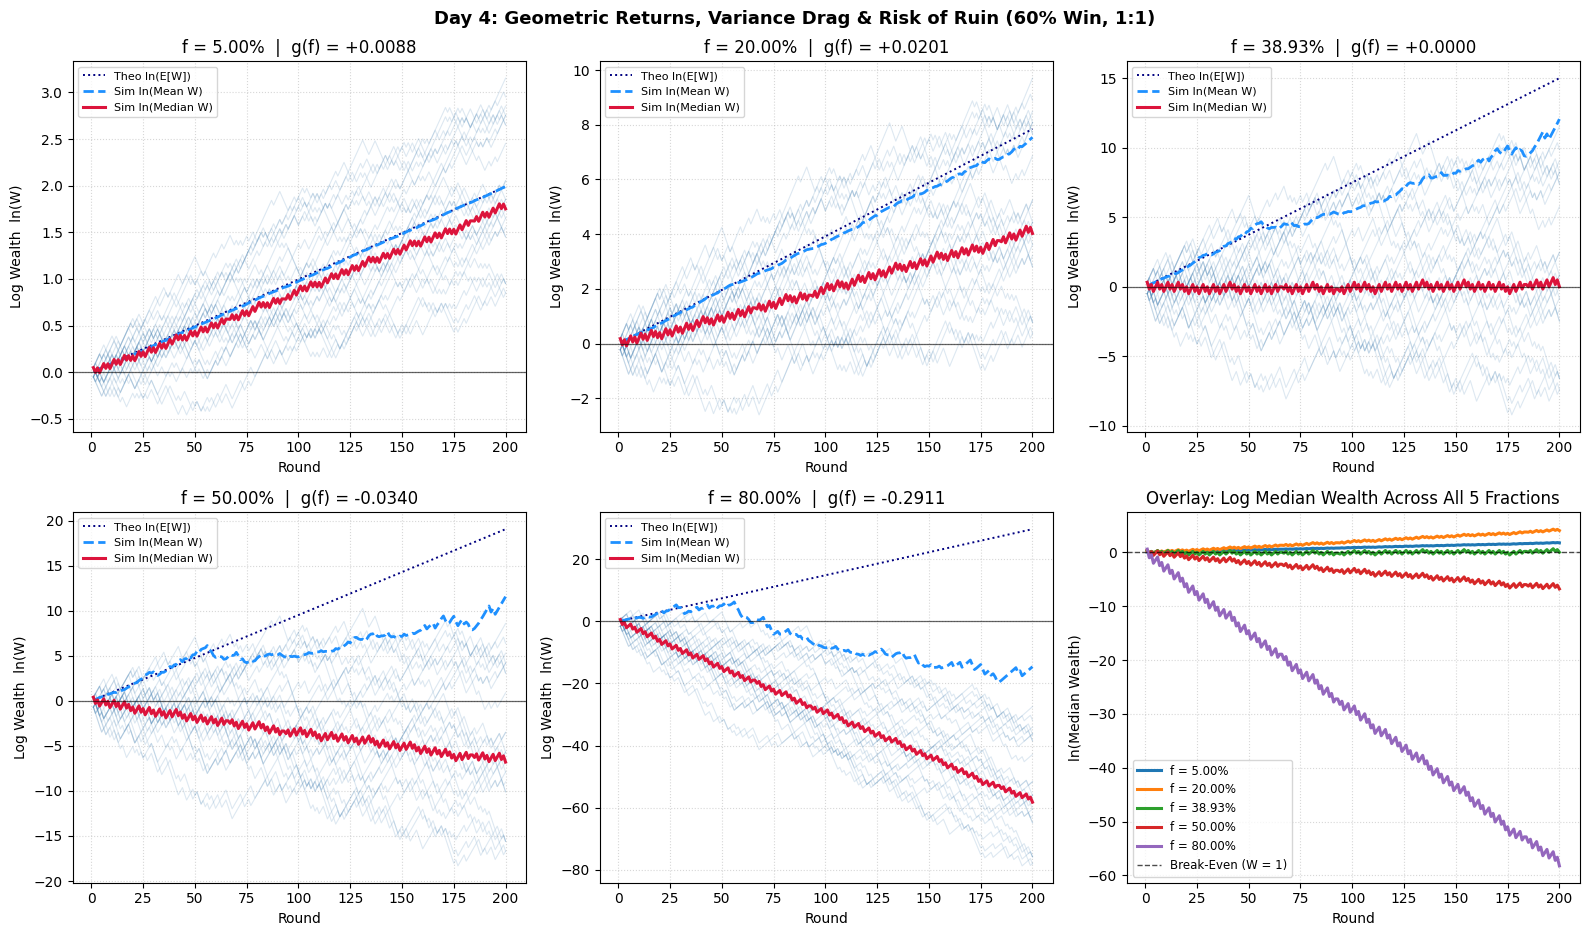

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)
n_paths = 1_000
n_rounds = 200
p_win = 0.60
fractions = [0.05, 0.20, 0.3893, 0.50, 0.80]

# Shared win/loss matrix so every bet fraction experiences identical luck
wins = rng.random(size=(n_paths, n_rounds)) < p_win
rounds = np.arange(1, n_rounds + 1)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
axes = axes.ravel()

print("=== PART 2 & PART 3: 60% Edge / 1:1 Payoff (1,000 Paths x 200 Rounds) ===")
header = (f"{'Frac':>7} | {'g(f)/rnd':>9} | {'Mean W_200':>11} | {'Med W_200':>11} | "
          f"{'% Profit':>8} | {'% Ruin(<0.1)':>12} | {'Med MaxDD':>9} | {'% DD>=50%':>9}")
print(header)
print("-" * len(header))

median_curves = {}

for ax, f in zip(axes[:5], fractions):
    # --- PART 2: Compound Wealth Simulation ---
    mult = np.where(wins, 1.0 + f, 1.0 - f)
    W = np.cumprod(mult, axis=1, dtype=np.float64)

    # Analytical 1-round log growth rate and theoretical log(E[W_t])
    g_f = p_win * np.log(1.0 + f) + (1.0 - p_win) * np.log(1.0 - f)
    theo_log_mean = rounds * np.log(1.0 + (2 * p_win - 1) * f)

    # Empirical log(Mean Wealth) vs log(Median Wealth)
    log_mean_W = np.log(W.mean(axis=0))
    log_median_W = np.log(np.median(W, axis=0))
    median_curves[f] = log_median_W

    # Round-200 stats
    final_W = W[:, -1]
    mean_w = final_W.mean()
    med_w = np.median(final_W)
    pct_profit = np.mean(final_W > 1.0) * 100
    pct_ruin = np.mean(final_W < 0.10) * 100

    # --- PART 3: Path-Dependent Drawdown Stress Test ---
    running_peak = np.maximum(1.0, np.maximum.accumulate(W, axis=1))
    drawdown = (W - running_peak) / running_peak
    max_dd = drawdown.min(axis=1)  # Worst peak-to-trough drop per path

    med_max_dd = np.median(max_dd) * 100
    pct_dd50 = np.mean(max_dd <= -0.50) * 100

    print(f"{f:7.4f} | {g_f:+9.5f} | {mean_w:11.3g} | {med_w:11.3g} | "
          f"{pct_profit:7.1f}% | {pct_ruin:11.1f}% | {med_max_dd:8.1f}% | {pct_dd50:8.1f}%")

    # --- Plot individual fraction panel ---
    ax.plot(rounds, np.log(W[:25].T), color='steelblue', alpha=0.18, linewidth=0.8)
    ax.plot(rounds, theo_log_mean, color='navy', linestyle=':', linewidth=1.4, label='Theo ln(E[W])')
    ax.plot(rounds, log_mean_W, color='dodgerblue', linestyle='--', linewidth=2.0, label='Sim ln(Mean W)')
    ax.plot(rounds, log_median_W, color='crimson', linewidth=2.2, label='Sim ln(Median W)')
    ax.axhline(0, color='black', linestyle='-', linewidth=0.9, alpha=0.6)

    ax.set_title(f'f = {f*100:.2f}%  |  g(f) = {g_f:+.4f}')
    ax.set_xlabel('Round')
    ax.set_ylabel('Log Wealth  ln(W)')
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(fontsize=8, loc='best')

# --- Panel 6: Direct Overlay of All 5 Log-Median Trajectories ---
ax_all = axes[5]
for f, curve in median_curves.items():
    ax_all.plot(rounds, curve, linewidth=2.2, label=f'f = {f*100:.2f}%')

ax_all.axhline(0, color='black', linestyle='--', linewidth=1.0, alpha=0.7, label='Break-Even (W = 1)')
ax_all.set_title('Overlay: Log Median Wealth Across All 5 Fractions')
ax_all.set_xlabel('Round')
ax_all.set_ylabel('ln(Median Wealth)')
ax_all.grid(True, linestyle=':', alpha=0.5)
ax_all.legend(fontsize=8.5, loc='lower left')

plt.suptitle('Day 4: Geometric Returns, Variance Drag & Risk of Ruin (60% Win, 1:1)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
